In [1]:
# import the necessary libraries
  
from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram

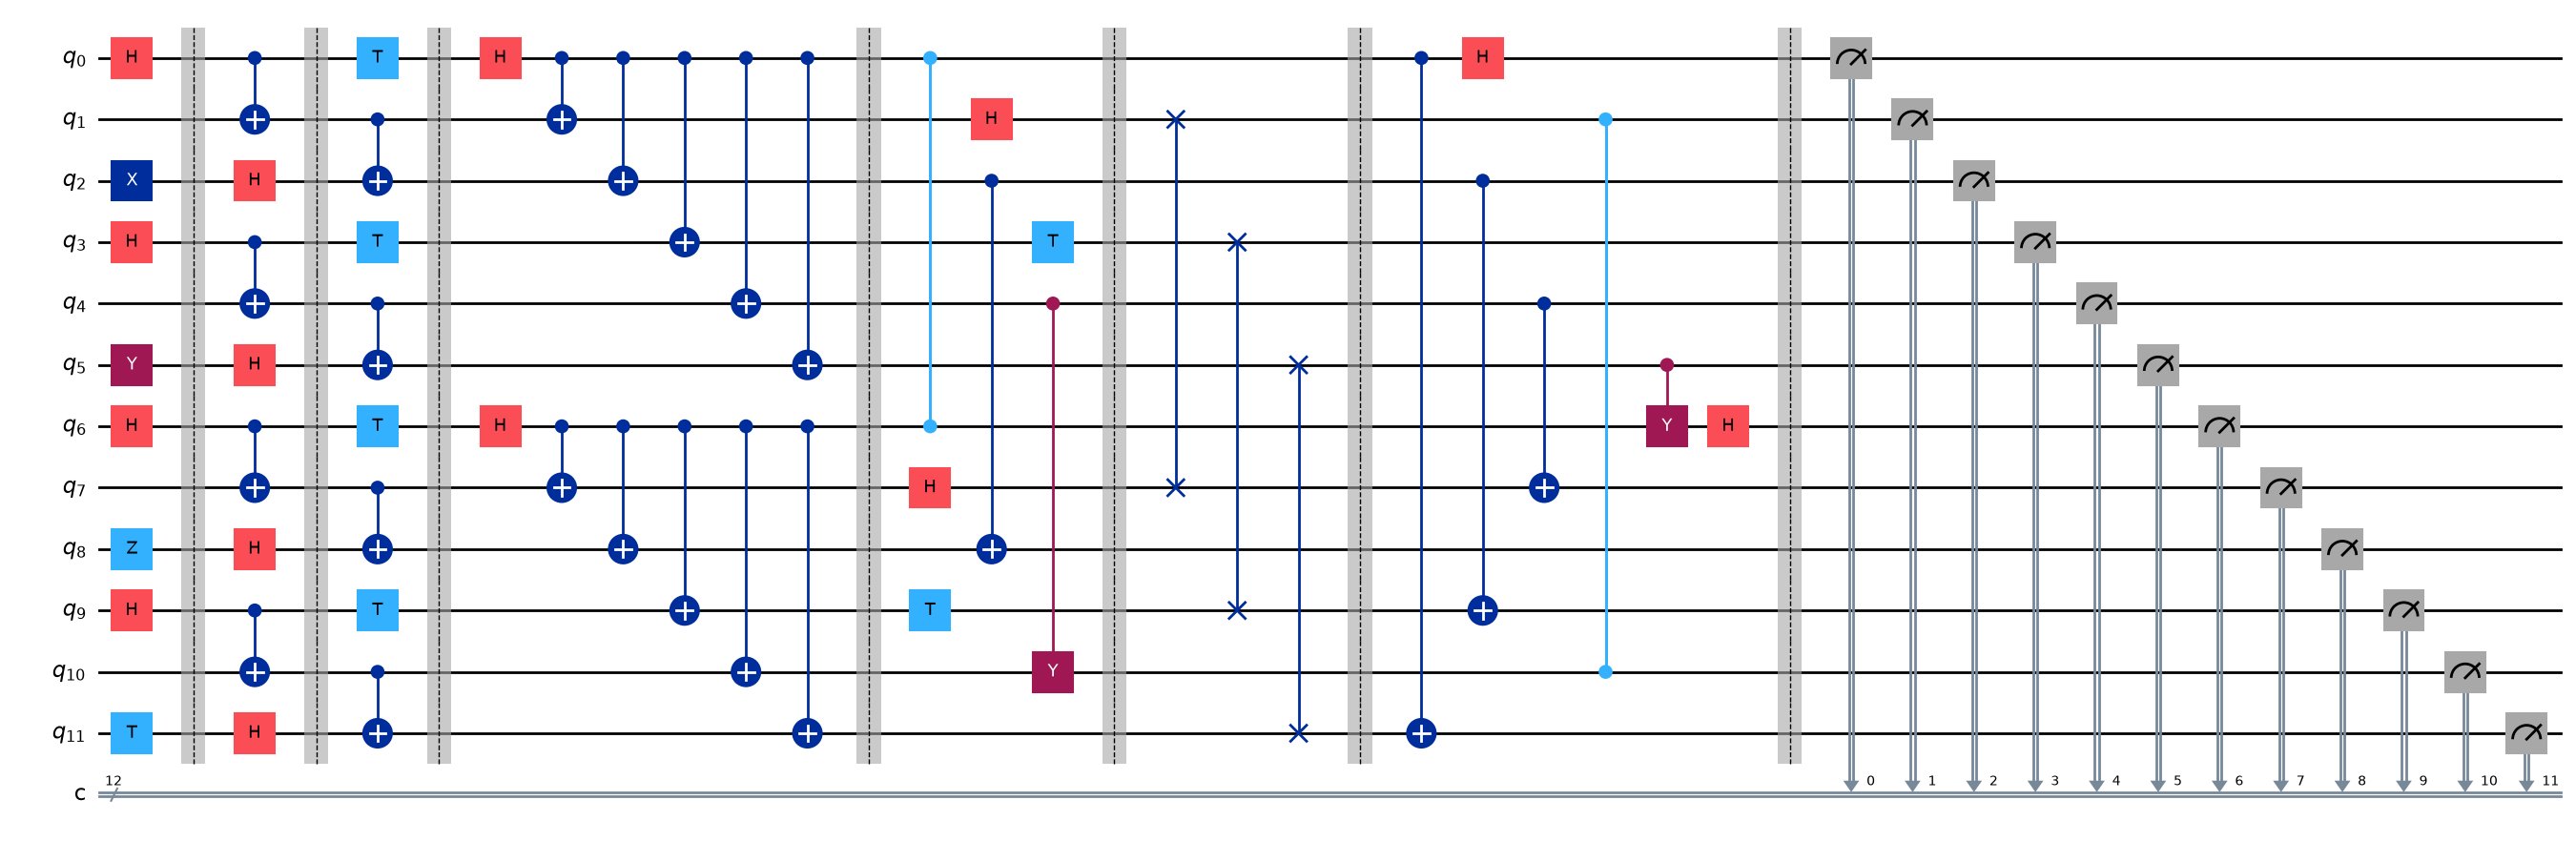

In [2]:
# 12 qubits and 12 classical bits
n = 12
qc = QuantumCircuit(n, 12)

# ==========================================
# LAYER 1: INITIAL SUPERPOSITION
# ==========================================

qc.h(0)
qc.h(3)
qc.h(6)
qc.h(9)

qc.x(2)
qc.y(5)
qc.z(8)
qc.t(11)

qc.barrier()

# ==========================================
# LAYER 2: FIRST ENTANGLEMENT NETWORK
# ==========================================

# Parallel CNOT connections
qc.cx(0, 1)
qc.cx(3, 4)
qc.cx(6, 7)
qc.cx(9, 10)

qc.h(2)
qc.h(5)
qc.h(8)
qc.h(11)

qc.barrier()

# ==========================================
# LAYER 3: INTERLEAVED ENTANGLEMENT
# ==========================================

qc.cx(1, 2)
qc.cx(4, 5)
qc.cx(7, 8)
qc.cx(10, 11)

qc.t(0)
qc.t(3)
qc.t(6)
qc.t(9)

qc.barrier()

# ==========================================
# LAYER 4: GHZ STATE GENERATION
# ==========================================

# First 6-qubit GHZ
qc.h(0)
qc.cx(0, 1)
qc.cx(0, 2)
qc.cx(0, 3)
qc.cx(0, 4)
qc.cx(0, 5)

# Second 6-qubit GHZ
qc.h(6)
qc.cx(6, 7)
qc.cx(6, 8)
qc.cx(6, 9)
qc.cx(6, 10)
qc.cx(6, 11)

qc.barrier()

# ==========================================
# LAYER 5: CROSS-GROUP INTERACTIONS
# ==========================================

qc.cz(0, 6)
qc.cx(2, 8)
qc.cy(4, 10)

qc.h(1)
qc.t(3)
qc.h(7)
qc.t(9)

qc.barrier()

# ==========================================
# LAYER 6: STATE EXCHANGE
# ==========================================

qc.swap(1, 7)
qc.swap(3, 9)
qc.swap(5, 11)

qc.barrier()

# ==========================================
# LAYER 7: FINAL ENTANGLEMENT
# ==========================================

qc.cx(0, 11)
qc.cx(2, 9)
qc.cx(4, 7)

qc.cz(1, 10)
qc.cy(5, 6)

qc.h(0)
qc.h(6)

qc.barrier()

# ==========================================
# MEASUREMENT
# ==========================================

qc.measure(range(12), range(12))

# Draw circuit
qc.draw("mpl", fold=-1)


In [3]:
# from qiskit.quantum_info import SparsePauliOp

# operator_strings = ['Z' + 'I' * i + 'Z' + 'I' * (n-2-i) for i in range(n-1)]
# print(operator_strings)
# print(len(operator_strings))

# operators = [SparsePauliOp(operator_strings) for operator_strings in operator_strings]
# print(operators)


from qiskit.quantum_info import SparsePauliOp
from qiskit_aer.primitives import Estimator

# Remove measurements for expectation-value calculation
qc_state = qc.remove_final_measurements(inplace=False)

# Generate all unique qubit-pair ZZ operators
pairs = [(i, j) for i in range(n) for j in range(i + 1, n)]

operators = [
    SparsePauliOp.from_sparse_list(
        [("ZZ", [i, j], 1.0)],
        num_qubits=n
    )
    for i, j in pairs
]

# Calculate expectation values
estimator = Estimator()

job = estimator.run(
    [qc_state] * len(operators),
    operators
)

result = job.result()
correlations = result.values

print("Number of qubit pairs:", len(pairs))
print("Number of expectation values:", len(correlations))


Number of qubit pairs: 66
Number of expectation values: 66


In [4]:
# from qiskit_aer.primitives import Estimator

# estimator = Estimator()
# job = estimator.run([qc] * len(operators), operators)
# job.result()


In [5]:
# import matplotlib.pyplot as plt

# data = list(range(1, len(operators) + 1))
# result = job.result()
# values = result.values
# values = [v / values[0] for v in values]

# plt.scatter(data, values, marker='o', label='100 qubits GHZ state')
# plt.xlabel('Distance between qubits $i$ and $j$')
# plt.ylabel(r'\langle Z_0 Z_i \rangle / \langle Z_0 Z_1 \rangle$')
# plt.legend()
# plt.show()

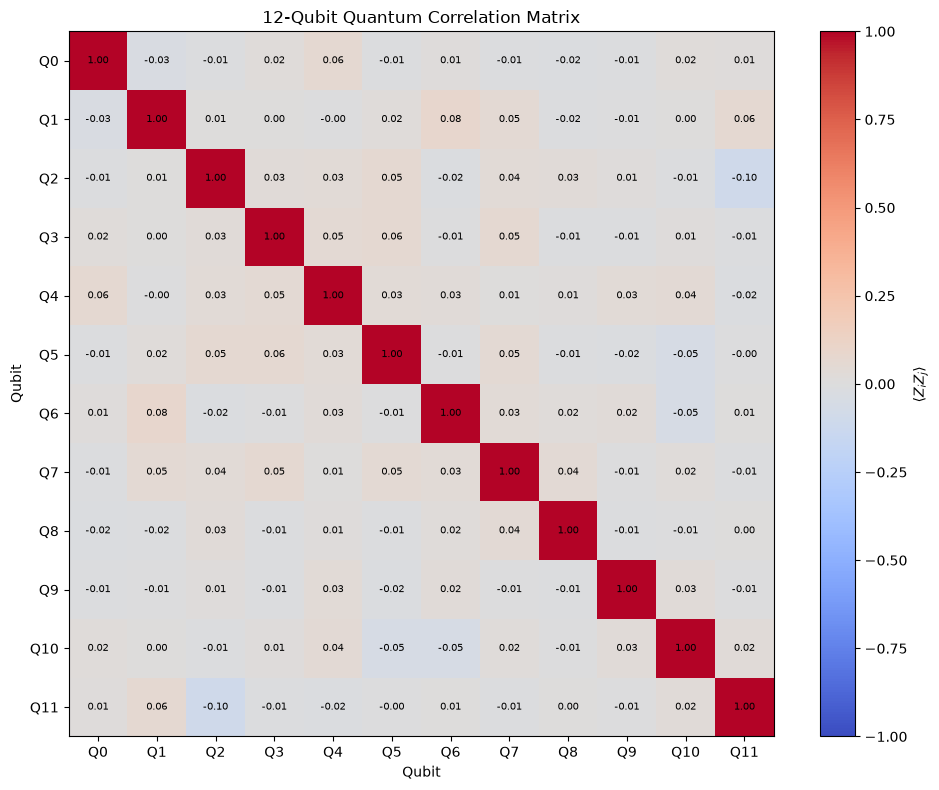

In [6]:

import numpy as np
import matplotlib.pyplot as plt

# Construct the 12 x 12 correlation matrix
corr_matrix = np.eye(n)

for (i, j), value in zip(pairs, correlations):
    corr_matrix[i, j] = value
    corr_matrix[j, i] = value

# Plot heatmap
plt.figure(figsize=(10, 8))

plt.imshow(
    corr_matrix,
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

plt.colorbar(label=r'$\langle Z_i Z_j \rangle$')

plt.xticks(range(n), [f'Q{i}' for i in range(n)])
plt.yticks(range(n), [f'Q{i}' for i in range(n)])

plt.title("12-Qubit Quantum Correlation Matrix")
plt.xlabel("Qubit")
plt.ylabel("Qubit")

# Display numerical values
for i in range(n):
    for j in range(n):
        plt.text(
            j, i,
            f"{corr_matrix[i,j]:.2f}",
            ha="center",
            va="center",
            fontsize=7
        )

plt.tight_layout()
plt.show()


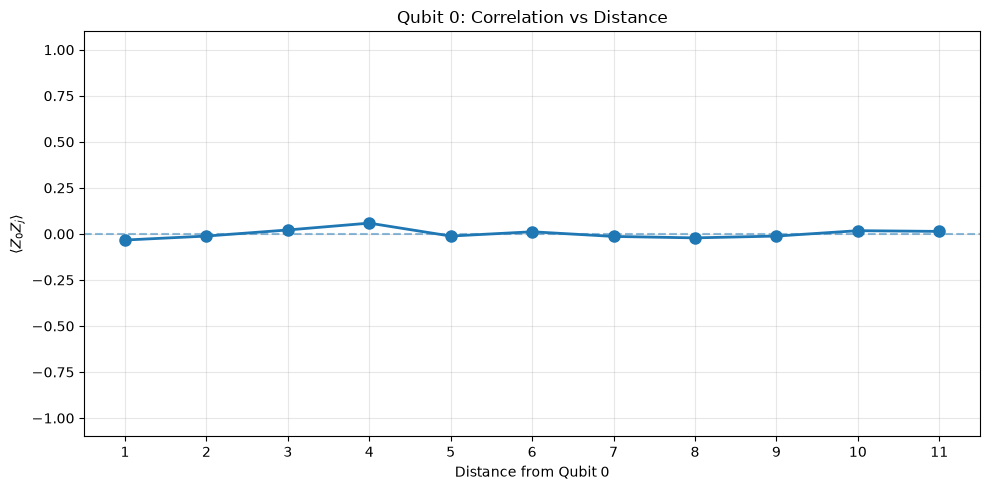

In [7]:

distances = np.arange(1, n)

correlation_values = [
    corr_matrix[0, j]
    for j in distances
]

plt.figure(figsize=(10, 5))

plt.plot(
    distances,
    correlation_values,
    marker='o',
    linewidth=2,
    markersize=8
)

plt.axhline(0, linestyle='--', alpha=0.5)

plt.xticks(distances)
plt.ylim(-1.1, 1.1)

plt.xlabel("Distance from Qubit 0")
plt.ylabel(r'$\langle Z_0 Z_j \rangle$')

plt.title("Qubit 0: Correlation vs Distance")

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


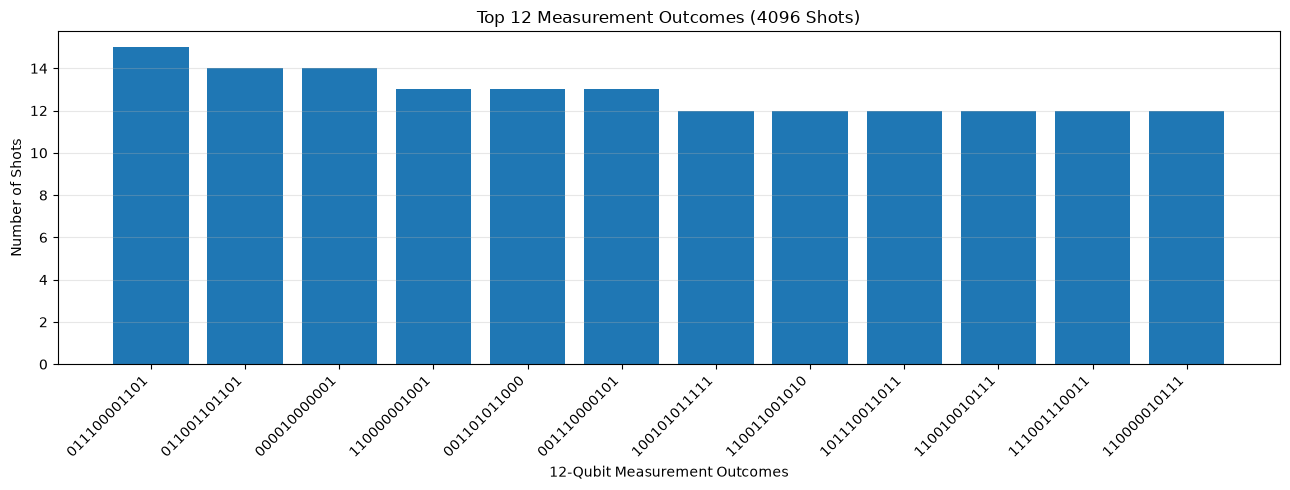

In [8]:

from qiskit_aer import AerSimulator
from qiskit import transpile
import matplotlib.pyplot as plt

# Execute circuit
simulator = AerSimulator()

compiled_circuit = transpile(qc, simulator)

job = simulator.run(
    compiled_circuit,
    shots=4096
)

counts = job.result().get_counts()

# Select top 12 measurement outcomes
top_counts = sorted(
    counts.items(),
    key=lambda x: x[1],
    reverse=True
)[:12]

labels = [item[0] for item in top_counts]
values = [item[1] for item in top_counts]

plt.figure(figsize=(13, 5))

plt.bar(labels, values)

plt.xlabel("12-Qubit Measurement Outcomes")
plt.ylabel("Number of Shots")
plt.title("Top 12 Measurement Outcomes (4096 Shots)")

plt.xticks(rotation=45, ha="right")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()
